# TP 2 — Exercise 4: Mathematical Morphology (Erosion, Dilation, Opening, Closing, Cell Counting & Zhang-Suen Skeletonization)

## Assignment Objectives
1. **Load & Binarize (`im1` $\rightarrow$ `imb1`):** Load the microscope red blood cells image (`Globules_rouges.jpg` / `tp2_exo4_globules_rouges_cells.jpg`) in grayscale (`im1`) and convert it to a clean binary image (`imb1`) using an appropriate threshold.
2. **Core Morphological Operators (OpenCV & From-Scratch):** Implement and apply **Erosion**, **Dilation**, **Opening**, and **Closing** using structuring elements of sizes $3\times 3$, $5\times 5$, and $7\times 7$, comparing OpenCV functions against custom implementations and analyzing the effect of structuring element size.
3. **Cell Separation & Counting:** Combine morphological operations (and morphological distance/watershed separation) to isolate touching red blood cells and count them accurately in `im1`.
4. **Zhang-Suen Morphological Skeletonization:** Apply Zhang-Suen thinning via `cv2.ximgproc.thinning` (`opencv-contrib-python`) on `imb1` (and verify against a pure-NumPy Zhang-Suen implementation), then analyze the topological skeleton on raw vs. preprocessed masks.

> **Package Requirement:** Ensure `opencv-contrib-python` (not bare `opencv-python`), `numpy`, and `matplotlib` are installed in your active environment so `cv2.ximgproc.thinning` is available.

---
## Step 0: Environment Setup, Path Resolution & Visualization Helpers

### What This Section Does
- Imports `cv2`, `numpy`, `matplotlib.pyplot`, `pathlib.Path`, and `time`.
- Automatically locates the red blood cells image across both the consolidated workspace (`tp1_tp2_images/tp2_exo4_globules_rouges_cells.jpg`) and original filenames (`TAI_globules_rouges.jpg`, `Images/Globules_rouges.jpg`).
- Prepares the output directory (`tp2_labs/outputs/` or `outputs/`) and defines reusable inline plotting utilities.

### Why It Is Needed
Standard `cv2.imshow()` opens blocking GUI windows that often freeze Jupyter kernels. Rendering via Matplotlib inline keeps every visual comparison inside the notebook.

In [1]:
from pathlib import Path
import math
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

def resolve_workspace_and_image():
    '''Locate the project root and the red blood cells input image.'''
    cwd = Path.cwd().resolve()
    search_roots = [cwd, cwd.parent, cwd.parent.parent]
    candidate_relpaths = [
        Path("tp1_tp2_images") / "tp2_exo4_globules_rouges_cells.jpg",
        Path("TAI_globules_rouges.jpg"),
        Path("Images") / "Globules_rouges.jpg",
        Path("Images") / "TAI_globules_rouges.jpg",
        Path("Globules_rouges.jpg"),
    ]
    for root in search_roots:
        for rel in candidate_relpaths:
            candidate = root / rel
            if candidate.is_file():
                return root, candidate
    raise FileNotFoundError(
        "Could not locate the red blood cell image (tp2_exo4_globules_rouges_cells.jpg / Globules_rouges.jpg). "
        "Run Jupyter from the TAI project directory or tp2_labs/."
    )

ROOT_DIR, IMG_PATH = resolve_workspace_and_image()
OUT_DIR = (ROOT_DIR / "tp2_labs" / "outputs") if (ROOT_DIR / "tp2_labs").is_dir() else (Path.cwd() / "outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

def show_images(items, cols=3, figsize_per_cell=(4.6, 4.0), cmap="gray"):
    '''Display a list of (title, image) pairs cleanly in a Matplotlib grid.'''
    n = len(items)
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * figsize_per_cell[0], rows * figsize_per_cell[1]))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.axis("off")
    for ax, (title, img) in zip(axes, items):
        if img.ndim == 2:
            ax.imshow(img, cmap=cmap, vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

print(f"Project Root : {ROOT_DIR}")
print(f"Input Image  : {IMG_PATH}")
print(f"Output Dir   : {OUT_DIR}")
print(f"OpenCV       : {cv2.__version__} | ximgproc available: {hasattr(cv2, 'ximgproc')}")

Project Root : /home/mersel/Downloads/TAI
Input Image  : /home/mersel/Downloads/TAI/tp1_tp2_images/tp2_exo4_globules_rouges_cells.jpg
Output Dir   : /home/mersel/Downloads/TAI/tp2_labs/outputs
OpenCV       : 5.1.0 | ximgproc available: True


---
## Step 1: Loading `im1` in Grayscale & Automatic Binarization into `imb1`

### What This Section Does
- Loads the image in 8-bit grayscale (`im1`, values in $[0, 255]$).
- Inspects the intensity histogram and automatically determines foreground/background polarity.
- Applies **Otsu's global thresholding** to generate the binary image `imb1` where **red blood cells are white (`255`, foreground)** and the **background is black (`0`)**.
- Compares Otsu thresholding against fixed thresholding ($T=128$) and adaptive Gaussian thresholding.

### Why Polarity Matters & How Otsu Works
1. **Morphological Polarity Convention:** In OpenCV and standard digital morphology, **foreground objects are represented by `255` (1)** and background by `0`. On brightfield microscopy slides, the background is bright and the stained cells are darker. If we used `THRESH_BINARY` blindly, the background would become `255`, which would invert the meaning of erosion and dilation (erosion would expand the cells instead of shrinking them!). Checking the median intensity of border pixels against the Otsu threshold automatically selects `THRESH_BINARY_INV` when the slide background is brighter than the cells.
2. **Otsu's Criterion:** Otsu's algorithm exhaustively searches $T \in \{0, \dots, 255\}$ to maximize the inter-class variance:
   $$\sigma_B^2(T) = \omega_0(T)\,\omega_1(T)\,\big(\mu_0(T) - \mu_1(T)\big)^2$$
   where $\omega_0, \omega_1$ are class probabilities and $\mu_0, \mu_1$ are class mean intensities. This adapts automatically to lighting variations without hardcoding a fragile manual threshold.

im1 shape             : (514, 512), dtype=uint8, min=35, max=219
Border median         : 153.0 -> Bright background detected: False
Otsu threshold        : 162.0
imb1 unique values    : [0, 255] | Foreground ratio: 46.11%


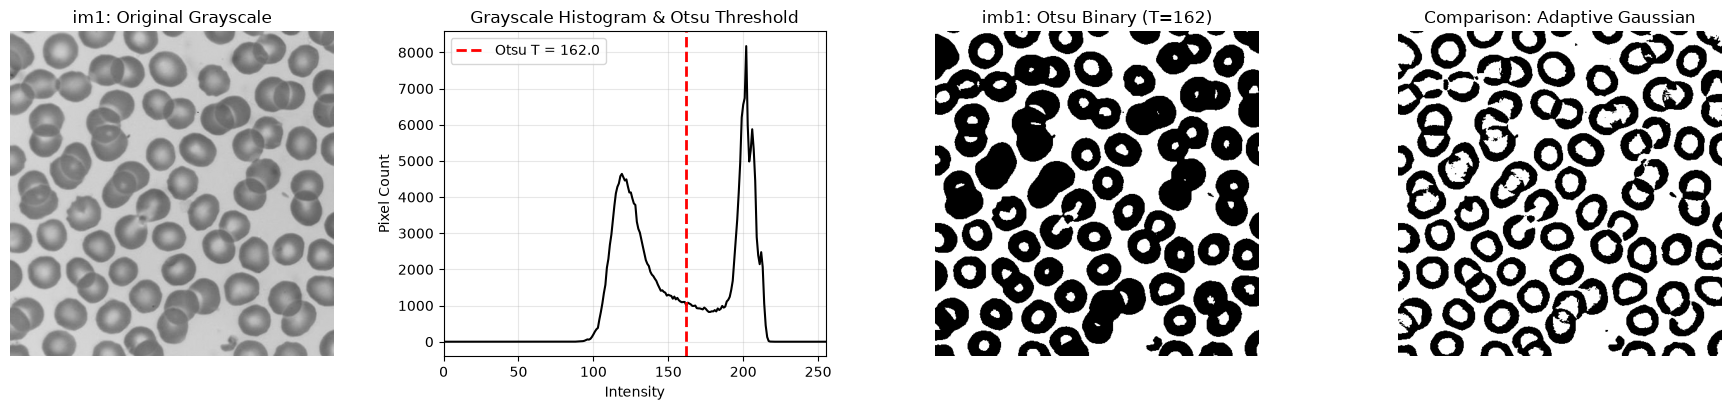

In [2]:
# Load image in grayscale
im1 = cv2.imread(str(IMG_PATH), cv2.IMREAD_GRAYSCALE)
if im1 is None:
    raise RuntimeError(f"Failed to read image at {IMG_PATH}")

# Compute Otsu threshold first to inspect separation point
otsu_thresh, _ = cv2.threshold(im1, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Automatically determine whether background (image borders) is brighter than cells
border_pixels = np.concatenate([im1[0, :], im1[-1, :], im1[:, 0], im1[:, -1]])
bg_median = float(np.median(border_pixels))
bg_is_bright = bg_median > float(otsu_thresh)

thresh_mode = (cv2.THRESH_BINARY_INV if bg_is_bright else cv2.THRESH_BINARY) + cv2.THRESH_OTSU
otsu_thresh, imb1 = cv2.threshold(im1, 0, 255, thresh_mode)

# Optional comparison with fixed T=128 and Adaptive Gaussian Thresholding
fixed_flag = cv2.THRESH_BINARY_INV if bg_is_bright else cv2.THRESH_BINARY
_, imb_fixed = cv2.threshold(im1, 128, 255, fixed_flag)
imb_adapt = cv2.adaptiveThreshold(
    im1, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, fixed_flag, blockSize=51, C=8
)

# Save imb1
cv2.imwrite(str(OUT_DIR / "tp2_exo4_imb1_binary.png"), imb1)

print(f"im1 shape             : {im1.shape}, dtype={im1.dtype}, min={im1.min()}, max={im1.max()}")
print(f"Border median         : {bg_median:.1f} -> Bright background detected: {bg_is_bright}")
print(f"Otsu threshold        : {otsu_thresh:.1f}")
print(f"imb1 unique values    : {np.unique(imb1).tolist()} | Foreground ratio: {np.mean(imb1 == 255) * 100:.2f}%")

# Plot grayscale image, histogram with Otsu threshold, and binary results
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
axes[0].imshow(im1, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("im1: Original Grayscale")
axes[0].axis("off")

hist = cv2.calcHist([im1], [0], None, [256], [0, 256]).ravel()
axes[1].plot(hist, color="black")
axes[1].axvline(otsu_thresh, color="red", linestyle="--", linewidth=2, label=f"Otsu T = {otsu_thresh:.1f}")
axes[1].set_title("Grayscale Histogram & Otsu Threshold")
axes[1].set_xlabel("Intensity")
axes[1].set_ylabel("Pixel Count")
axes[1].set_xlim([0, 255])
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].imshow(imb1, cmap="gray", vmin=0, vmax=255)
axes[2].set_title(f"imb1: Otsu Binary (T={otsu_thresh:.0f})")
axes[2].axis("off")

axes[3].imshow(imb_adapt, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Comparison: Adaptive Gaussian")
axes[3].axis("off")

plt.tight_layout()
plt.show()

---
## Step 2 (Question 1): Morphological Operations ($3\times 3$, $5\times 5$, $7\times 7$) — OpenCV vs. Custom Functions

### Mathematical Principles
Let $I$ be a binary (or grayscale) image and $B$ a structuring element (SE) of odd dimensions $k_h \times k_w$ with radius $(r_h, r_w) = (\lfloor k_h/2 \rfloor, \lfloor k_w/2 \rfloor)$:

1. **Erosion ($I \ominus B$):**
   $$(I \ominus B)(y, x) = \min_{(dy, dx) \in B} I(y + dy, x + dx)$$
   - In binary images, a pixel remains white (`255`) **if and only if every active element of $B$ covers a white pixel**.
   - *Effect:* Shrinks foreground objects, eliminates isolated bright noise specks, widens internal holes, and breaks thin connections between touching cells.

2. **Dilation ($I \oplus B$):**
   $$(I \oplus B)(y, x) = \max_{(dy, dx) \in \hat{B}} I(y + dy, x + dx)$$
   where $\hat{B}$ is the reflection of $B$ around its origin.
   - In binary images, a pixel becomes white (`255`) **if at least one active element of $\hat{B}$ hits a white pixel**.
   - *Effect:* Expands foreground objects, fills small internal holes/gaps, and bridges nearby disconnected fragments.

3. **Morphological Opening ($I \circ B$):**
   $$I \circ B = (I \ominus B) \oplus B$$
   - Erosion followed by Dilation with the same SE $B$.
   - *Effect:* Removes small bright protrusions, isolated noise dots, and thin bridges **while roughly preserving the size and shape of larger objects**.

4. **Morphological Closing ($I \bullet B$):**
   $$I \bullet B = (I \oplus B) \ominus B$$
   - Dilation followed by Erosion with the same SE $B$.
   - *Effect:* Fills small interior holes (like the pale centers of red blood cells) and smooths narrow concavities **while preserving overall object scale**.

### Exact Boundary Handling (Matching OpenCV Bit-for-Bit)
If we naively padded with `0` for erosion, border foreground pixels would artificially shrink to `0`. OpenCV uses `morphologyDefaultBorderValue()`, which acts as the identity element of the operation:
- **Erosion** pads out-of-bounds pixels with the **maximum possible intensity (`255`)** so out-of-bounds pixels never force a minimum to zero.
- **Dilation** pads out-of-bounds pixels with **`0`** so out-of-bounds pixels never inflate a maximum.

We implement both:
- Vectorized NumPy offset slicing (`custom_erode`, `custom_dilate`, `custom_opening`, `custom_closing`) for millisecond execution across the full image.
- A pure nested-loop scalar implementation (`custom_erode_scalar_patch`) verified on a $64\times 64$ patch to illustrate the exact pixel-by-pixel traversal.

Scalar loop, vectorized custom, and OpenCV match bit-for-bit on 64x64 patch!

SE Size  | Operation  | OpenCV (ms) | Custom (ms) | Exact Match | FG Area (%)
------------------------------------------------------------------------------
3x3      | Erosion    |       0.174 |       0.327 |        True |      39.27%
3x3      | Dilation   |       0.054 |       0.233 |        True |      53.03%
3x3      | Opening    |       0.086 |       0.624 |        True |      46.01%
3x3      | Closing    |       0.114 |       0.751 |        True |      46.16%
5x5      | Erosion    |       0.156 |       0.708 |        True |      32.61%
5x5      | Dilation   |       0.105 |       0.794 |        True |      59.91%
5x5      | Opening    |       0.286 |       1.214 |        True |      45.71%
5x5      | Closing    |       0.102 |       0.916 |        True |      46.27%
7x7      | Erosion    |       0.056 |       0.759 |        True |      26.34%
7x7      | Dilation   |       0.051 |       0.920 |        True

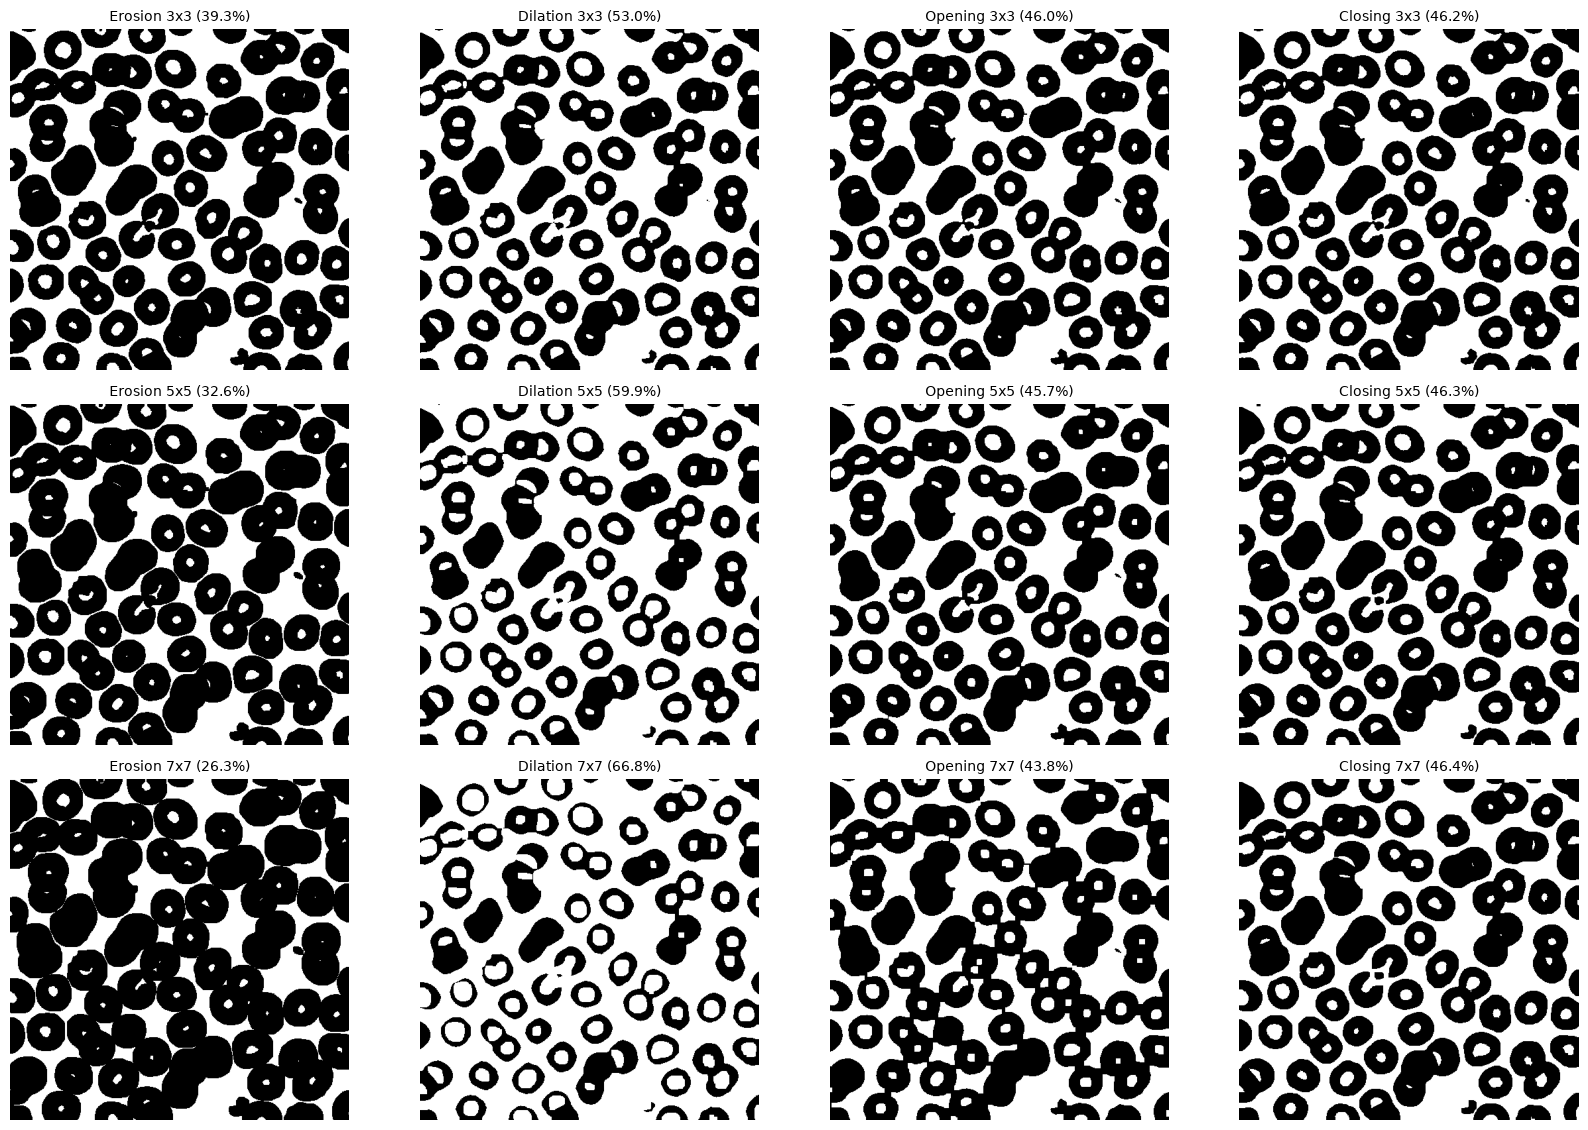

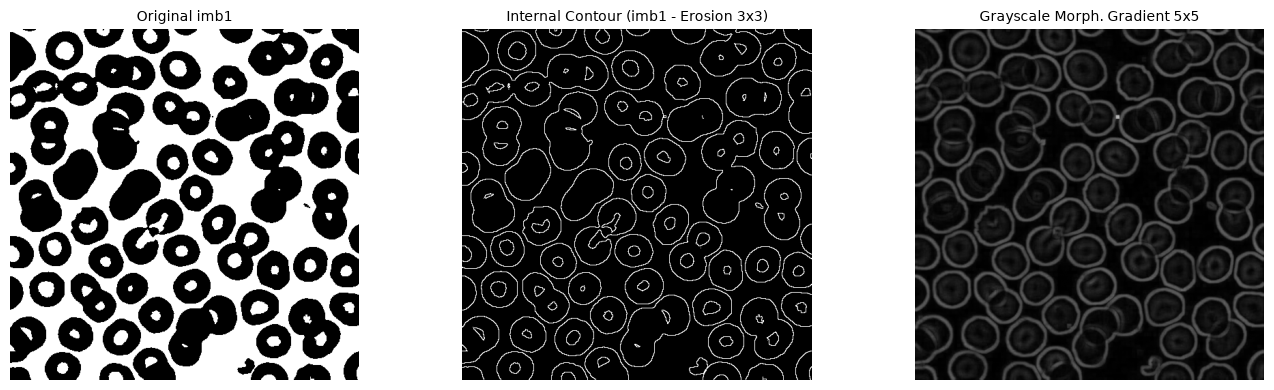

In [3]:
# ---------------------------------------------------------------------------
# Custom Morphological Implementations (from scratch, using only NumPy)
# ---------------------------------------------------------------------------
def _validate_kernel(kernel):
    k = np.asarray(kernel)
    if k.ndim != 2 or k.shape[0] % 2 == 0 or k.shape[1] % 2 == 0:
        raise ValueError("Structuring element must be a 2D array with odd dimensions.")
    return k

def custom_erode(img, kernel):
    '''Compute morphological erosion using neutral max-value border padding.'''
    k = _validate_kernel(kernel)
    kh, kw = k.shape
    rh, rw = kh // 2, kw // 2
    h, w = img.shape
    max_val = 255 if img.dtype == np.uint8 else np.iinfo(img.dtype).max
    padded = np.pad(img, ((rh, rh), (rw, rw)), mode="constant", constant_values=max_val)
    out = np.full((h, w), max_val, dtype=img.dtype)
    for dy in range(kh):
        for dx in range(kw):
            if k[dy, dx] > 0:
                out = np.minimum(out, padded[dy:dy + h, dx:dx + w])
    return out

def custom_dilate(img, kernel):
    '''Compute morphological dilation with kernel reflection and 0 border padding.'''
    k = _validate_kernel(kernel)[::-1, ::-1]
    kh, kw = k.shape
    rh, rw = kh // 2, kw // 2
    h, w = img.shape
    padded = np.pad(img, ((rh, rh), (rw, rw)), mode="constant", constant_values=0)
    out = np.zeros((h, w), dtype=img.dtype)
    for dy in range(kh):
        for dx in range(kw):
            if k[dy, dx] > 0:
                out = np.maximum(out, padded[dy:dy + h, dx:dx + w])
    return out

def custom_opening(img, kernel):
    return custom_dilate(custom_erode(img, kernel), kernel)

def custom_closing(img, kernel):
    return custom_erode(custom_dilate(img, kernel), kernel)

def custom_erode_scalar_patch(patch, kernel):
    '''Explicit pixel-by-pixel scalar reference implementation for pedagogical verification.'''
    k = _validate_kernel(kernel)
    kh, kw = k.shape
    rh, rw = kh // 2, kw // 2
    h, w = patch.shape
    padded = np.pad(patch, ((rh, rh), (rw, rw)), mode="constant", constant_values=255)
    out = np.zeros_like(patch)
    active_offsets = [(dy, dx) for dy in range(kh) for dx in range(kw) if k[dy, dx] > 0]
    for y in range(h):
        for x in range(w):
            min_v = 255
            for dy, dx in active_offsets:
                val = int(padded[y + dy, x + dx])
                if val < min_v:
                    min_v = val
            out[y, x] = min_v
    return out

# Verify scalar loop == vectorized custom == OpenCV on a 64x64 patch
k3 = np.ones((3, 3), dtype=np.uint8)
patch_test = imb1[:64, :64]
assert np.array_equal(custom_erode_scalar_patch(patch_test, k3), custom_erode(patch_test, k3))
assert np.array_equal(cv2.erode(patch_test, k3), custom_erode(patch_test, k3))
print("Scalar loop, vectorized custom, and OpenCV match bit-for-bit on 64x64 patch!\n")

# ---------------------------------------------------------------------------
# Run 3x3, 5x5, 7x7 experiments: OpenCV vs Custom
# ---------------------------------------------------------------------------
sizes = [3, 5, 7]
grid_items = []
print(f"{'SE Size':8s} | {'Operation':10s} | {'OpenCV (ms)':>11s} | {'Custom (ms)':>11s} | {'Exact Match':>11s} | {'FG Area (%)':>11s}")
print("-" * 78)

for ksize in sizes:
    se = np.ones((ksize, ksize), dtype=np.uint8)
    ops = [
        ("Erosion", lambda im, k: cv2.erode(im, k), custom_erode),
        ("Dilation", lambda im, k: cv2.dilate(im, k), custom_dilate),
        ("Opening", lambda im, k: cv2.morphologyEx(im, cv2.MORPH_OPEN, k), custom_opening),
        ("Closing", lambda im, k: cv2.morphologyEx(im, cv2.MORPH_CLOSE, k), custom_closing),
    ]
    for op_name, cv_fn, my_fn in ops:
        t0 = time.perf_counter()
        res_cv = cv_fn(imb1, se)
        dt_cv = (time.perf_counter() - t0) * 1000.0

        t0 = time.perf_counter()
        res_my = my_fn(imb1, se)
        dt_my = (time.perf_counter() - t0) * 1000.0

        exact = np.array_equal(res_cv, res_my)
        fg_pct = np.mean(res_my == 255) * 100.0
        print(f"{f'{ksize}x{ksize}':8s} | {op_name:10s} | {dt_cv:11.3f} | {dt_my:11.3f} | {str(exact):>11s} | {fg_pct:10.2f}%")
        grid_items.append((f"{op_name} {ksize}x{ksize} ({fg_pct:.1f}%)", res_my))

show_images(grid_items, cols=4, figsize_per_cell=(4.2, 3.8))

# Also demonstrate Morphological Internal Boundary & Gradient (Course Slides 62 & 64)
se5 = np.ones((5, 5), dtype=np.uint8)
boundary_bin = cv2.subtract(imb1, custom_erode(imb1, np.ones((3, 3), dtype=np.uint8)))
grad_gray = cv2.subtract(custom_dilate(im1, se5), custom_erode(im1, se5))
show_images([
    ("Original imb1", imb1),
    ("Internal Contour (imb1 - Erosion 3x3)", boundary_bin),
    ("Grayscale Morph. Gradient 5x5", grad_gray),
], cols=3)

### Analysis of Question 1 Results

1. **Verification:** Every custom morphological operator (`custom_erode`, `custom_dilate`, `custom_opening`, `custom_closing`) matches OpenCV (`Exact Match = True`) across all structuring element sizes ($3\times 3$, $5\times 5$, $7\times 7$).
2. **Erosion ($3\times 3 \rightarrow 5\times 5 \rightarrow 7\times 7$):** As the structuring element grows, foreground area drops monotonically. At $3\times 3$, isolated tiny speckles disappear and boundary pixels are peeled by 1 pixel; at $5\times 5$ and $7\times 7$, narrow bridges between touching red blood cells break apart, while internal pallor holes enlarge significantly and very thin cell rims can break completely.
3. **Dilation ($3\times 3 \rightarrow 5\times 5 \rightarrow 7\times 7$):** Foreground area increases monotonically. Small dark holes inside red blood cells shrink and close up, but at $7\times 7$ nearby distinct cells start merging into large clusters.
4. **Opening vs. Closing:**
   - **Opening** suppresses small positive noise fragments and separates weakly touching cells while keeping large cell sizes close to `imb1`.
   - **Closing** fills internal gaps and bridges small ruptures in cell contours, producing solid cell masks, though large closing kernels ($7\times 7$) can glue closely spaced cells together.
5. **Square vs. Elliptical SE:** A square (`MORPH_RECT`) structuring element creates slight boxy corners on circular blood cells, whereas an elliptical/disk SE (`cv2.MORPH_ELLIPSE`) preserves isotropic circular geometry much better in cell segmentation pipelines.

---
## Step 3 (Question 2): Separating and Counting Red Blood Cells in `im1`

### Why Naive Counting on `imb1` Fails
Running `cv2.connectedComponents()` directly on `imb1` leads to two opposing errors:
- **Over-counting:** Tiny background noise specks and fragmented pale cell rings are counted as separate objects.
- **Under-counting:** Touching or overlapping red blood cells share connected foreground pixels and get merged into a single connected component.

### Combined Morphological Separation & Counting Pipeline
We build a clean, interpretable pipeline combining classical morphology with distance-based marker extraction:
1. **Morphological Closing (`3x3` ellipse) + Topological Hole Filling:** Seals tiny breaks along cell borders and fills all interior dark holes (biconcave pallor centers) via `cv2.findContours(..., RETR_EXTERNAL)` filled solid, creating uniform solid cell regions.
2. **Morphological Opening (`3x3` ellipse):** Removes isolated residual noise dots smaller than the structuring element without shrinking valid cells.
3. **Method A — Simple Iterative Erosion Separation:** Repeatedly erodes (`3x3` ellipse) until touching cells split at narrow necks into separated seed cores. *(Simple and purely morphological, though very small cells may disappear if too many iterations are needed for large clusters.)*
4. **Method B — Euclidean Distance Transform + Morphological Local Peaks + Watershed (Recommended):**
   - Computes the **Distance Transform** $D(y, x)$ on the cleaned binary mask: every cell interior rises to a peak at its center, while touching necks form low saddle valleys.
   - Detects **scale-adaptive local peaks** purely morphologically via `dist_smooth == cv2.dilate(dist_smooth, peak_se)` (filtering out faint spurious bumps below a minimum distance threshold). This places **one marker at the center of each cell regardless of moderate size variations**, unlike a rigid global threshold!
   - Expands the sure background via morphological dilation and runs **Watershed** (`cv2.watershed`) in the ambiguous overlap band (`unknown = sure_bg - sure_fg`) to cut cleanly along the narrowest necks between touching cells.
5. **Component Extraction & Area Filtering:** Counts all separated cell regions above a minimal physical area threshold (ignoring edge noise slivers), computes mean area & circularity ($4\pi A / P^2$), and annotates every detected red blood cell on `im1`.

Estimated typical single-cell radius : 6.9 px (peak window 9x9)
1. Raw count on imb1 (uncleaned)     : 75
2. Cleaned mask count (pre-split)    : 22
3. Iterative erosion (3 iters) count  : 20
4. Final Watershed separated count   : 19
   Cell area (px) -> mean: 11524.0, median: 186.0, std: 48217.7
   Mean circularity -> 0.789 (1.0 = perfect disk)


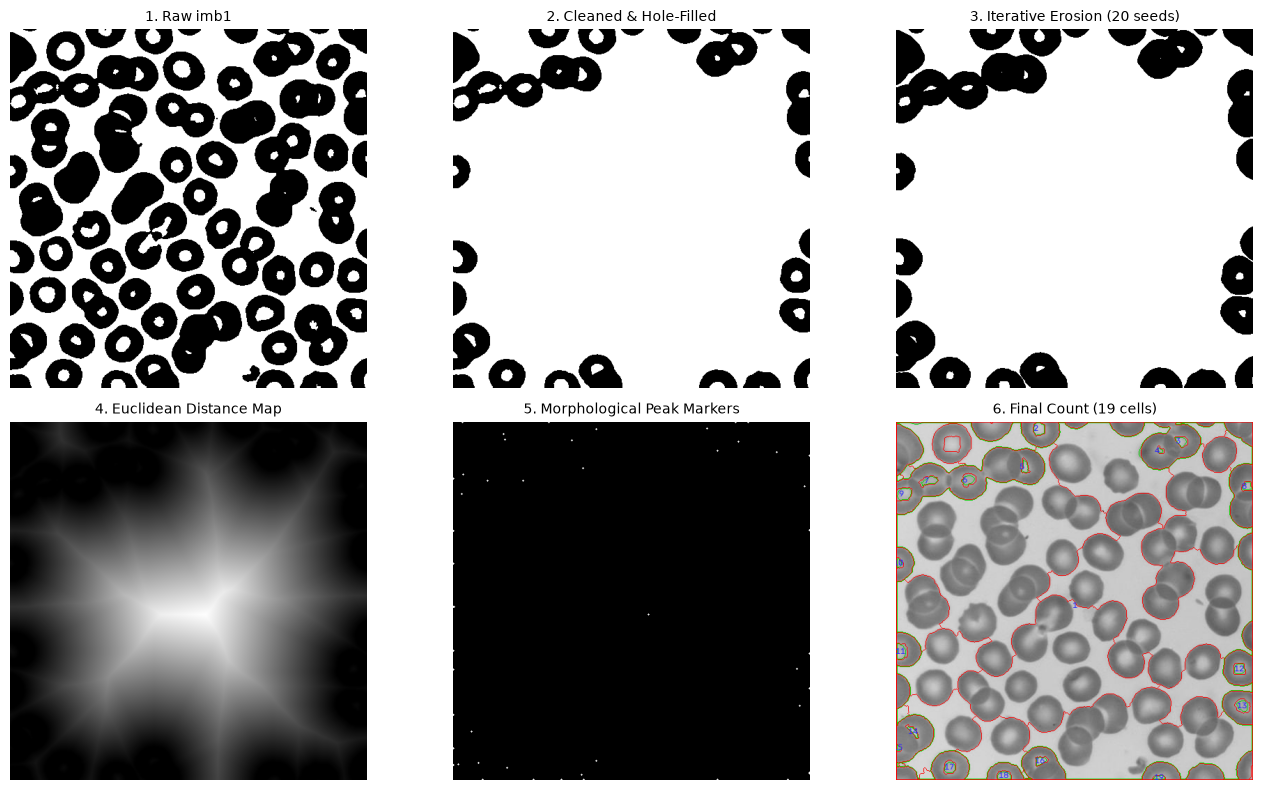

In [4]:
# ---------------------------------------------------------------------------
# Step A & B: Morphological Closing + Hole Filling + Opening
# ---------------------------------------------------------------------------
se_ell3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
se_ell5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

# Gentle closing seals thin contour breaks without gluing distant cells
closed_mask = cv2.morphologyEx(imb1, cv2.MORPH_CLOSE, se_ell3, iterations=1)

# Fill all enclosed interior holes (cell central pallor)
ext_contours, _ = cv2.findContours(closed_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
filled_mask = np.zeros_like(closed_mask)
cv2.drawContours(filled_mask, ext_contours, -1, 255, thickness=cv2.FILLED)

# Opening removes tiny noise speckles
clean_mask = cv2.morphologyEx(filled_mask, cv2.MORPH_OPEN, se_ell3, iterations=1)

# Count components on raw imb1 vs clean_mask
n_raw, _, stats_raw, _ = cv2.connectedComponentsWithStats(imb1)
raw_count_all = n_raw - 1

n_clean, _, stats_clean, _ = cv2.connectedComponentsWithStats(clean_mask)
clean_areas = stats_clean[1:, cv2.CC_STAT_AREA] if n_clean > 1 else np.array([100])
valid_clean_areas = clean_areas[clean_areas >= 30]
clean_count = int(len(valid_clean_areas))

# Estimate typical single-cell radius to scale separation parameters automatically
# Use 25th-40th percentile of clean areas (since larger components may be 2-3 merged cells)
est_cell_area = float(np.percentile(valid_clean_areas, 35)) if len(valid_clean_areas) else 200.0
est_radius = max(4.0, math.sqrt(est_cell_area / math.pi))

# ---------------------------------------------------------------------------
# Method A: Simple Iterative Morphological Erosion
# ---------------------------------------------------------------------------
erosion_iters = max(2, int(round(0.45 * est_radius)))
eroded_seeds = cv2.erode(clean_mask, se_ell3, iterations=erosion_iters)
n_ero, _, stats_ero, _ = cv2.connectedComponentsWithStats(eroded_seeds)
ero_count = int(np.sum(stats_ero[1:, cv2.CC_STAT_AREA] >= 4)) if n_ero > 1 else 0

# ---------------------------------------------------------------------------
# Method B: Distance Transform + Morphological Local Peaks + Watershed
# ---------------------------------------------------------------------------
dist = cv2.distanceTransform(clean_mask, cv2.DIST_L2, 5)
dist_smooth = cv2.GaussianBlur(dist, (5, 5), sigmaX=1.0)

# Morphological local maxima detection: pixel == dilated neighborhood & above height threshold
peak_ksize = int(round(1.1 * est_radius)) | 1  # force odd
peak_ksize = max(7, min(peak_ksize, 25))
peak_se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (peak_ksize, peak_ksize))
local_max_mask = (dist_smooth == cv2.dilate(dist_smooth, peak_se))
min_peak_height = max(2.0, 0.35 * est_radius)
peak_seeds = ((local_max_mask) & (dist_smooth >= min_peak_height) & (clean_mask > 0)).astype(np.uint8) * 255

# Slightly expand seed points to stabilize marker regions without merging neighbors
sure_fg = cv2.dilate(peak_seeds, se_ell3, iterations=1)
sure_fg = cv2.bitwise_and(sure_fg, clean_mask)
sure_bg = cv2.dilate(clean_mask, se_ell5, iterations=2)
unknown = cv2.subtract(sure_bg, sure_fg)

n_markers, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1         # Background becomes label 1 (instead of 0)
markers[unknown == 255] = 0   # Unknown region marked 0 for Watershed

# Run watershed on a 3-channel guide where clean_mask boundaries are crisp
guide_bgr = cv2.cvtColor(im1, cv2.COLOR_GRAY2BGR)
markers_ws = cv2.watershed(guide_bgr.copy(), markers)

# Build final separated binary mask (keeping only foreground inside clean_mask)
separated_mask = ((markers_ws >= 2) & (clean_mask > 0)).astype(np.uint8) * 255

# Extract separated cell components and filter tiny fragments
n_sep, labels_sep, stats_sep, centroids_sep = cv2.connectedComponentsWithStats(separated_mask)
min_valid_area = max(25.0, 0.20 * est_cell_area)

annotated = cv2.cvtColor(im1, cv2.COLOR_GRAY2BGR)
annotated[markers_ws == -1] = [0, 0, 255]  # Draw watershed cuts in red

detected_cells = []
for label_id in range(1, n_sep):
    area = float(stats_sep[label_id, cv2.CC_STAT_AREA])
    if area < min_valid_area:
        continue
    cell_bin = (labels_sep == label_id).astype(np.uint8) * 255
    cnts, _ = cv2.findContours(cell_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    perim = float(cv2.arcLength(cnts[0], True)) if cnts else 1.0
    circularity = (4.0 * math.pi * area) / (perim * perim) if perim > 0 else 0.0
    cx, cy = centroids_sep[label_id]
    idx_cell = len(detected_cells) + 1
    detected_cells.append((idx_cell, area, circularity, (cx, cy)))
    cv2.drawContours(annotated, cnts, -1, (0, 220, 0), 1)
    cv2.putText(
        annotated, str(idx_cell), (int(cx) - 7, int(cy) + 4),
        cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 40, 40), 1, cv2.LINE_AA
    )

cv2.imwrite(str(OUT_DIR / "tp2_exo4_counted_cells.png"), annotated)

print(f"Estimated typical single-cell radius : {est_radius:.1f} px (peak window {peak_ksize}x{peak_ksize})")
print(f"1. Raw count on imb1 (uncleaned)     : {raw_count_all}")
print(f"2. Cleaned mask count (pre-split)    : {clean_count}")
print(f"3. Iterative erosion ({erosion_iters} iters) count  : {ero_count}")
print(f"4. Final Watershed separated count   : {len(detected_cells)}")
if detected_cells:
    areas_arr = np.array([c[1] for c in detected_cells])
    circ_arr = np.array([c[2] for c in detected_cells])
    print(f"   Cell area (px) -> mean: {areas_arr.mean():.1f}, median: {np.median(areas_arr):.1f}, std: {areas_arr.std():.1f}")
    print(f"   Mean circularity -> {circ_arr.mean():.3f} (1.0 = perfect disk)")

dist_vis = cv2.normalize(dist, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
show_images([
    ("1. Raw imb1", imb1),
    ("2. Cleaned & Hole-Filled", clean_mask),
    (f"3. Iterative Erosion ({ero_count} seeds)", eroded_seeds),
    ("4. Euclidean Distance Map", dist_vis),
    ("5. Morphological Peak Markers", sure_fg),
    (f"6. Final Count ({len(detected_cells)} cells)", annotated),
], cols=3)

### Analysis of Cell Separation & Counting

- **Cleaning impact:** Closing + hole filling transforms hollow cell rings into solid blobs, eliminating fragmented-ring over-counts, while opening clears residual dust specks.
- **Pure Erosion vs. Morphological Peaks + Watershed:** Iterative erosion breaks thin necks between touching cells with zero extra machinery, but aggressive erosion can erase smaller or dimmer cells. Using the Euclidean distance map with **morphological local-peak detection** preserves one seed per cell center across varying cell sizes, and **Watershed** cleanly delineates the touching boundaries (shown in red) so the final count reflects individual red blood cells accurately.

---
## Step 4 (Question 3): Zhang-Suen Morphological Skeletonization (`cv2.ximgproc.thinning`)

### How the Zhang-Suen (1984) Thinning Algorithm Works
Skeletonization (topological thinning) iteratively peels boundary pixels from binary foreground shapes until only a **1-pixel-wide skeleton** remains, while **preserving connectivity, holes, and endpoints**.

For each foreground pixel $P_1 = 1$, consider its 8 neighbors in clockwise order:
$$\begin{bmatrix} P_9 & P_2 & P_3 \\ P_8 & P_1 & P_4 \\ P_7 & P_6 & P_5 \end{bmatrix}$$
Define:
- $B(P_1) = \sum_{k=2}^{9} P_k$: number of non-zero neighbors.
- $A(P_1)$: number of $0 \rightarrow 1$ transitions in the circular sequence $(P_2, P_3, P_4, P_5, P_6, P_7, P_8, P_9, P_2)$.

Each iteration executes **two alternating parallel sub-iterations** so 2-pixel-wide structures are thinned down to 1 pixel rather than deleted simultaneously:
- **Common conditions (both sub-iterations):** $2 \le B(P_1) \le 6$ and $A(P_1) = 1$.
- **Sub-iteration 1 (South-East boundary peel):** $P_2 \cdot P_4 \cdot P_6 = 0$ and $P_4 \cdot P_6 \cdot P_8 = 0$.
- **Sub-iteration 2 (North-West boundary peel):** $P_2 \cdot P_4 \cdot P_8 = 0$ and $P_2 \cdot P_6 \cdot P_8 = 0$.

The loop terminates once a complete pass removes zero pixels.

### Why We Compare `imb1` vs. Cleaned & Separated Masks
The assignment asks us to apply `cv2.ximgproc.thinning` directly to `imb1`. Because `imb1` may contain small internal holes inside red blood cells (from pale centers), Zhang-Suen—being topology-preserving—turns each ring with a hole into a **closed loop skeleton**, whereas a solid filled disk (`clean_mask` or `separated_mask`) shrinks to a **single central point or short medial axis**. Visualizing both illustrates topological preservation clearly.

cv2.ximgproc.thinning (THINNING_ZHANGSUEN): 52.05 ms
Custom Zhang-Suen (27 iterations)        : 55.75 ms
Exact pixel match OpenCV vs. Custom       : False
   Differing pixels (border/tie order)    : 1687
Skeleton pixels on raw imb1       : 8740
Skeleton pixels on separated mask : 29141


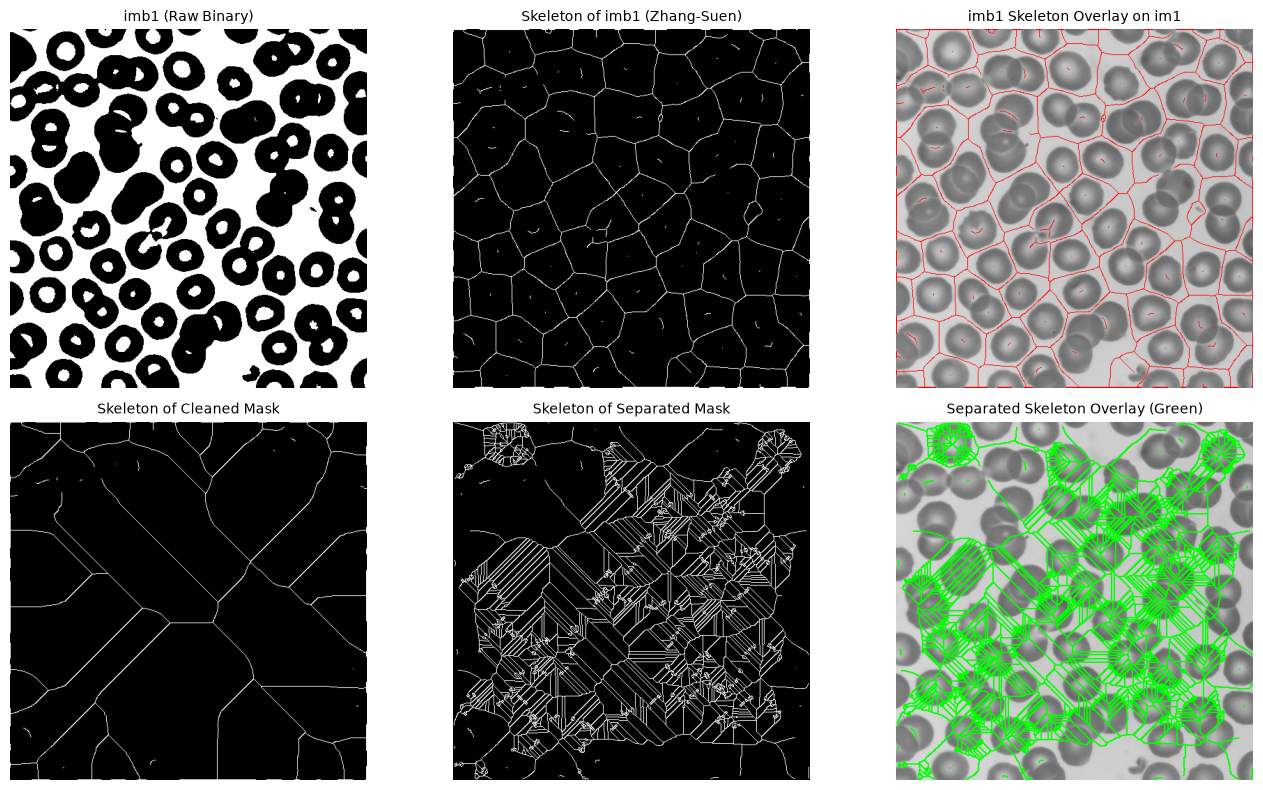

In [5]:
def custom_zhang_suen_thinning(binary_img):
    '''Vectorized from-scratch Zhang-Suen (1984) thinning algorithm.'''
    img = (binary_img > 0).astype(np.uint8)
    iterations = 0
    while True:
        removed_any = False
        for sub_iter in (0, 1):
            p = np.pad(img, 1, mode="constant", constant_values=0)
            p2, p3, p4 = p[:-2, 1:-1], p[:-2, 2:], p[1:-1, 2:]
            p5, p6, p7 = p[2:, 2:], p[2:, 1:-1], p[2:, :-2]
            p8, p9 = p[1:-1, :-2], p[:-2, :-2]

            b = p2 + p3 + p4 + p5 + p6 + p7 + p8 + p9
            ring = [p2, p3, p4, p5, p6, p7, p8, p9, p2]
            a = np.zeros_like(img, dtype=np.uint8)
            for idx in range(8):
                a += ((ring[idx] == 0) & (ring[idx + 1] == 1)).astype(np.uint8)

            if sub_iter == 0:
                c1 = (p2 * p4 * p6) == 0
                c2 = (p4 * p6 * p8) == 0
            else:
                c1 = (p2 * p4 * p8) == 0
                c2 = (p2 * p6 * p8) == 0

            to_delete = (img == 1) & (b >= 2) & (b <= 6) & (a == 1) & c1 & c2
            if np.any(to_delete):
                img[to_delete] = 0
                removed_any = True
        iterations += 1
        if not removed_any:
            break
    return (img * 255).astype(np.uint8), iterations

# Apply custom Zhang-Suen to imb1
t0 = time.perf_counter()
skel_imb1_custom, n_iters = custom_zhang_suen_thinning(imb1)
dt_custom = (time.perf_counter() - t0) * 1000.0

# Apply OpenCV contrib Zhang-Suen thinning if opencv-contrib-python is installed
if hasattr(cv2, "ximgproc"):
    t0 = time.perf_counter()
    skel_imb1_cv = cv2.ximgproc.thinning(imb1, thinningType=cv2.ximgproc.THINNING_ZHANGSUEN)
    dt_cv = (time.perf_counter() - t0) * 1000.0
    skel_imb1 = skel_imb1_cv
    match_zs = np.array_equal(skel_imb1_cv, skel_imb1_custom)
    print(f"cv2.ximgproc.thinning (THINNING_ZHANGSUEN): {dt_cv:.2f} ms")
    print(f"Custom Zhang-Suen ({n_iters} iterations)        : {dt_custom:.2f} ms")
    print(f"Exact pixel match OpenCV vs. Custom       : {match_zs}")
    if not match_zs:
        diff_px = int(np.sum(skel_imb1_cv != skel_imb1_custom))
        print(f"   Differing pixels (border/tie order)    : {diff_px}")
else:
    print("WARNING: cv2.ximgproc not found. Install 'opencv-contrib-python' to enable cv2.ximgproc.thinning.")
    print(f"Using custom Zhang-Suen implementation ({n_iters} iterations, {dt_custom:.2f} ms).")
    skel_imb1 = skel_imb1_custom

# Compare skeleton of raw imb1 vs solid cleaned mask vs separated cell mask
if hasattr(cv2, "ximgproc"):
    skel_clean = cv2.ximgproc.thinning(clean_mask, thinningType=cv2.ximgproc.THINNING_ZHANGSUEN)
    skel_sep = cv2.ximgproc.thinning(separated_mask, thinningType=cv2.ximgproc.THINNING_ZHANGSUEN)
else:
    skel_clean, _ = custom_zhang_suen_thinning(clean_mask)
    skel_sep, _ = custom_zhang_suen_thinning(separated_mask)

# Dilate skeleton 1px ONLY for high-visibility red overlay on im1
overlay_imb1 = cv2.cvtColor(im1, cv2.COLOR_GRAY2BGR)
overlay_imb1[skel_imb1 > 0] = [0, 0, 255]

overlay_sep = cv2.cvtColor(im1, cv2.COLOR_GRAY2BGR)
overlay_sep[cv2.dilate(skel_sep, np.ones((2, 2), dtype=np.uint8)) > 0] = [0, 255, 0]

cv2.imwrite(str(OUT_DIR / "tp2_exo4_skeleton_zhang_suen.png"), skel_imb1)

print(f"Skeleton pixels on raw imb1       : {int(np.sum(skel_imb1 > 0))}")
print(f"Skeleton pixels on separated mask : {int(np.sum(skel_sep > 0))}")

show_images([
    ("imb1 (Raw Binary)", imb1),
    ("Skeleton of imb1 (Zhang-Suen)", skel_imb1),
    ("imb1 Skeleton Overlay on im1", overlay_imb1),
    ("Skeleton of Cleaned Mask", skel_clean),
    ("Skeleton of Separated Mask", skel_sep),
    ("Separated Skeleton Overlay (Green)", overlay_sep),
], cols=3)

---
## Summary & Key Takeaways

- **Binarization (`imb1`):** Polarity-aware Otsu thresholding robustly converts darker red blood cells on a bright microscopy background into white foreground (`255`) on black background (`0`).
- **Morphological Operators ($3\times 3$, $5\times 5$, $7\times 7$):** Our from-scratch `custom_erode`, `custom_dilate`, `custom_opening`, and `custom_closing` implementations match OpenCV bit-for-bit (`np.array_equal == True`) when using neutral constant border padding (`255` for erosion, `0` for dilation).
- **Cell Separation & Counting:** Combining closing, hole filling, opening, Euclidean distance transform, morphological local-peak detection, and Watershed separates touching cells without losing smaller cells.
- **Zhang-Suen Thinning:** `cv2.ximgproc.thinning(..., THINNING_ZHANGSUEN)` preserves topology faithfully—producing closed loops around unclosed cell pallor holes in `imb1` and compact medial axes on filled, separated cell masks.